In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("listings_clean.csv")
print(df.shape)

(29918, 84)


room_type,Entire home/apt,Hotel room,Private room,Shared room
neighbourhood_group_cleansed,,,,
Bronx,136.0,210.0,80.0,NaN
Brooklyn,196.0,315.0,101.0,107.0
Manhattan,255.0,754.0,255.0,57.0
Queens,161.0,459.0,90.0,110.0
Staten Island,118.0,NaN,92.0,110.0


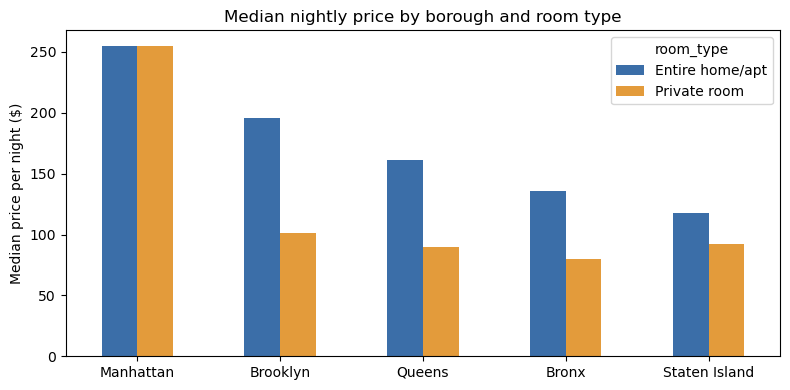

In [3]:
# EDA 1: median price by borough and room type
priced = df[df["price"].notna()]
table = priced.pivot_table(index="neighbourhood_group_cleansed", columns="room_type",
                           values="price", aggfunc="median").round(0)
display(table)

# Chart: entire homes vs private rooms in each borough
order = ["Manhattan", "Brooklyn", "Queens", "Bronx", "Staten Island"]
table.loc[order, ["Entire home/apt", "Private room"]].plot(kind="bar", figsize=(8, 4), color=["#3B6EA8", "#E39B3B"])
plt.ylabel("Median price per night ($)")
plt.xlabel("")
plt.title("Median nightly price by borough and room type")
plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig("eda_price_borough.png"); plt.show()

In [4]:
# EDA 2: why are Manhattan private rooms so expensive?
mp = priced[(priced["neighbourhood_group_cleansed"] == "Manhattan") & (priced["room_type"] == "Private room")]
print("Manhattan private rooms with a price:", len(mp))
print(mp["property_type"].value_counts().head(5))
print("\nMedian price, short stay (<30 nights) vs 30+ nights:")
print(mp.groupby("short_stay")["price"].median())

Manhattan private rooms with a price: 2894
property_type
Private room in rental unit    1268
Room in hotel                  1119
Private room in condo           110
Room in boutique hotel          106
Private room in townhouse        98
Name: count, dtype: int64

Median price, short stay (<30 nights) vs 30+ nights:
short_stay
False     89.895
True     510.015
Name: price, dtype: float64


license_status,exempt,none,registered
30+ nights,0.2,99.5,0.3
Under 30 nights,49.0,13.4,37.6


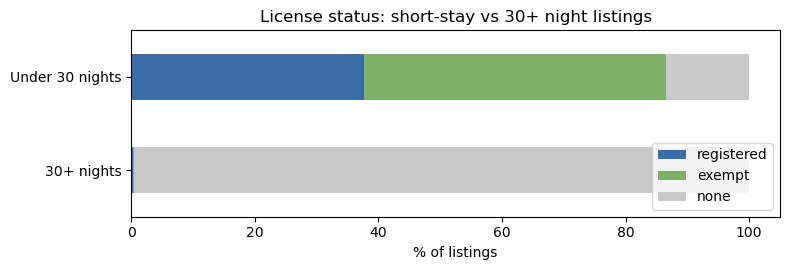

In [5]:
# EDA 3: license status for short-stay vs 30+ night listings
ct = pd.crosstab(df["short_stay"], df["license_status"], normalize="index").mul(100).round(1)
ct.index = ["30+ nights", "Under 30 nights"]
display(ct)

ct[["registered", "exempt", "none"]].plot(kind="barh", stacked=True, figsize=(8, 2.8),
                                          color=["#3B6EA8", "#7FB069", "#C9C9C9"])
plt.xlabel("% of listings")
plt.title("License status: short-stay vs 30+ night and listings")
plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("eda_license.png"); plt.show()

,listings,pct_entire_home,pct_short_stay,median_price,median_availability,pct_has_reviews
host_type,,,,,,
10+ listings,8076,60.3,20.4,223.0,269.0,55.3
1–9 listings,21842,52.8,18.9,171.1,179.0,79.4


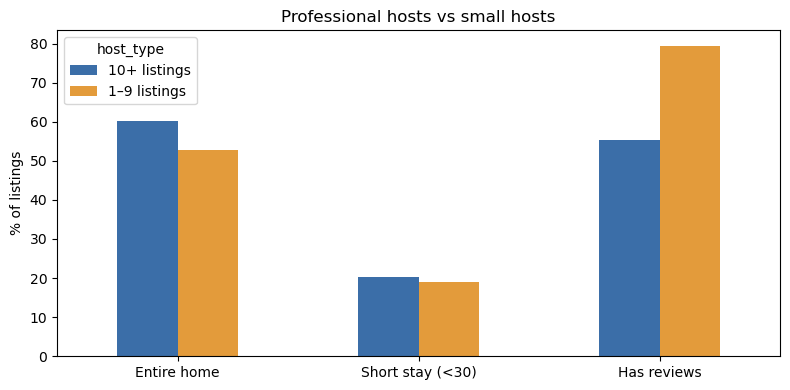

In [6]:
# EDA 4: do professional hosts (10+ listings) behave differently?
df["host_type"] = np.where(df["professional_host"], "10+ listings", "1–9 listings")
comp = df.groupby("host_type").agg(
    listings=("id", "count"),
    pct_entire_home=("room_type", lambda s: (s == "Entire home/apt").mean() * 100),
    pct_short_stay=("short_stay", lambda s: s.mean() * 100),
    median_price=("price", "median"),
    median_availability=("availability_365", "median"),
    pct_has_reviews=("has_reviews", lambda s: s.mean() * 100)).round(1)
display(comp)

comp[["pct_entire_home", "pct_short_stay", "pct_has_reviews"]].T.plot(kind="bar", figsize=(8, 4), color=["#3B6EA8", "#E39B3B"])
plt.ylabel("% of listings")
plt.xticks([0, 1, 2], ["Entire home", "Short stay (<30)", "Has reviews"], rotation=0)
plt.title("Professional hosts vs small hosts")
plt.tight_layout(); plt.savefig("eda_hosts.png"); plt.show()

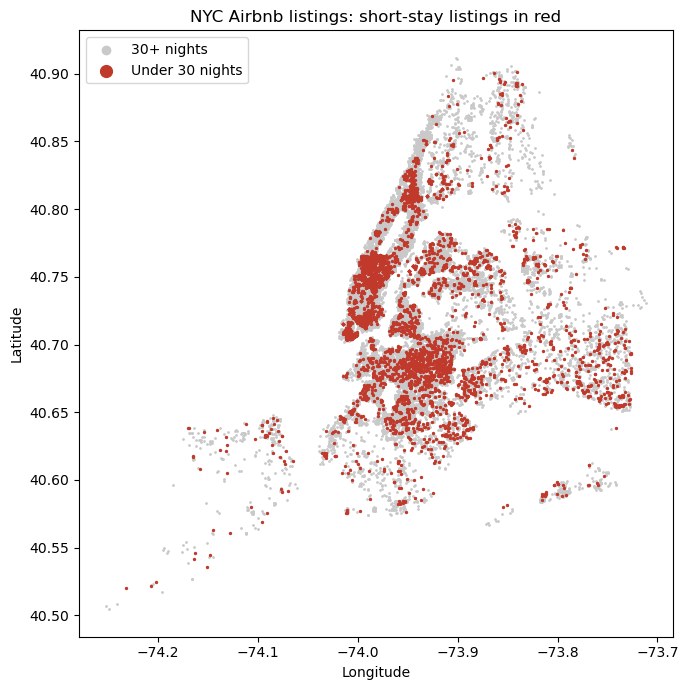

In [7]:
# EDA 5: where are short-stay listings? (lat/long map)
fig, ax = plt.subplots(figsize=(7, 7))
long_stay = df[~df["short_stay"]]
short = df[df["short_stay"]]
ax.scatter(long_stay["longitude"], long_stay["latitude"], s=1, color="#C9C9C9", label="30+ nights")
ax.scatter(short["longitude"], short["latitude"], s=2, color="#C0392B", label="Under 30 nights")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("NYC Airbnb listings: short-stay listings in red")
ax.legend(markerscale=6)
plt.tight_layout(); plt.savefig("eda_map.png"); plt.show()

In [8]:
# Numbers used in the report
print("Short-stay listings with no license info:", (df["short_stay"] & (df["license_status"] == "none")).sum())
print(df.groupby("neighbourhood_group_cleansed")["short_stay"].mean().mul(100).round(1))

Short-stay listings with no license info: 775
neighbourhood_group_cleansed
Bronx            15.2
Brooklyn         15.0
Manhattan        23.4
Queens           17.9
Staten Island    16.8
Name: short_stay, dtype: float64
